# Self-learning solver: only the last layer is trained (tf.function graph)

Variant of `Self_learning_Loeser_plastiche_dehnung_berechnung.ipynb`.

* The meta-pretrained hybrid spiking network (3x `HSNN` + `DSNN` + `Dense(240)` + `Dense(64)`) is **frozen**.
  For one return-mapping solve its input and recurrent states are fixed, so it is evaluated **once per solve** and
  yields a 64-dim feature vector.
* Only the output layer `Dense(1)` (64 weights + 1 bias) is optimised online. Δε_p = max_val · sigmoid(w·φ + b).
* Frozen forward pass **and** the whole optimisation loop (residual, exact gradient, Adam update, convergence check)
  run as **one fused, XLA-compiled `tf.function` call** per solve (`fused_solve`); all float inputs are packed into
  one vector. Adam's state persists between solves (`ADAM_RESET`, default `'never'`).
* The consistency residual is written entirely in TF ops (float64), so the gradient through J_N is exact.
* The last-layer weights are **not reset** between solves / Gauss points (self-learning, as in the original).
* At every solve the author's classical regula-falsi solver (`Klassich_implicit.ipynb`) is evaluated on the
  same trial state for comparison; a second run drives the whole integration with the classical solver.
* **Flow direction:** `N_plas = Z_N / J_N` as in `Klassich_implicit.ipynb`. The original self-learning notebook uses
  `Z_N / h_N`, which is larger by the factor alpha_N (consistency: J_N / alpha_N = h_N, normal n = 3/2 · Z_N / J_N).
  A third run (classical solver, `Z_N / h_N`) shows the effect of the original formulation.


In [1]:
# 0. Libraries
import os, copy, time, pickle
import numpy as np
import tensorflow as tf
USE_GPU = False   # tiny scalar graph loop: CPU is ~8x faster than GPU (kernel-launch overhead)
if not USE_GPU:
    tf.config.set_visible_devices([], 'GPU')
import matplotlib.pyplot as plt
from datetime import datetime
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from decoding import DSNN
from Hybrid_Spiking_Neuron import HSNN
%matplotlib inline

In [2]:
# 1. Configuration  -- adapt the paths to your machine
WEIGHTS_PATH = r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Trained_Model\meta_pretrainiertes_model\meta_weights_HSNN_up_different_scaling_more_innerloop.pkl"
STRAIN_DIR   = r"C:\Users\Tandale\sciebo\olddata\Phd\Writing\SLMU_paper\BVPs\Stress-Strain_Data_csv\BVP4_100_els"   # strain1<l><m><n>.csv

# Integration points (l, m, n) to integrate; all 45 of element 1: [(l, m, n) for l in range(3) for m in range(3) for n in range(5)]
POINTS       = [(0, 0, 0)]
INCREMENTS   = 15        # time increments (as in the original notebook)
LR           = 0.003     # Adam learning rate of the online optimisation (as in the original)
USE_XLA      = True      # compile the optimisation loop with XLA (tf.function(jit_compile=True))
ADAM_RESET   = 'never'   # when Adam's moments/step counter are reset: 'solve' (every solve, as in the original),
                         # 'increment' (first solve of each increment), 'never' (only at the start of a run)
TOL         = 1e-7      # convergence: residual**2 < TOL (as in the original)
MAX_ITER_P0  = 5000      # max optimiser steps in the first plane-stress iteration (as in the original)
MAX_ITER     = 1000      # max optimiser steps in later plane-stress iterations (as in the original)

# 1. Network: frozen feature extractor + trainable last layer

In [3]:
with open(WEIGHTS_PATH, "rb") as f:
    loaded_weights = pickle.load(f)

def build_feature_model(w):
    """Same architecture / weights as model_klassiche_up in the original notebook, cut before Dense(1)."""
    layer1 = tf.keras.layers.RNN(HSNN(208, thr=1e-7), return_sequences=True, return_state=True)
    layer2 = tf.keras.layers.RNN(HSNN(208, thr=1e-7), return_sequences=True, return_state=True)
    layer3 = tf.keras.layers.RNN(HSNN(208, thr=1e-7), return_sequences=True, return_state=True)
    layer5 = tf.keras.layers.RNN(DSNN(208, thr=1e-7), return_sequences=True, return_state=True)
    layer7 = Dense(240, activation='tanh')
    layer8 = Dense(64, activation='tanh')
    layer1.build((None, None, 12));  layer1.set_weights(w[0:2])
    layer2.build((None, None, 208)); layer2.set_weights(w[2:4])
    layer3.build((None, None, 208)); layer3.set_weights(w[4:6])
    layer5.build((None, None, 208)); layer5.set_weights(w[6:8])
    layer7.build((None, None, 208)); layer7.set_weights(w[8:10])
    layer8.build((None, 240));       layer8.set_weights(w[10:12])

    inputs = Input((None, 12))
    states = [Input(shape=(208,)) for _ in range(8)]
    X,  h1, c1 = layer1(inputs, initial_state=states[0:2])
    X2, h2, c2 = layer2(X,      initial_state=states[2:4])
    X3, h3, c3 = layer3(X2,     initial_state=states[4:6])
    V,  h4, c4 = layer5(X3,     initial_state=states[6:8])
    feats      = layer8(layer7(tf.math.tanh(V)))
    m = Model([inputs] + states, [feats, h1, c1, h2, c2, h3, c3, h4, c4])
    m.trainable = False
    return m

feature_model = build_feature_model(loaded_weights)
STATE_KEYS    = ('state_h_', 'state_c_', 'state_h1_', 'state_c1_', 'state_h2_', 'state_c2_', 'state_h3_', 'state_c3_')
STATE_UNITS   = 208

# trainable last layer Dense(1), initialised with the meta-pretrained weights (float64)
W = tf.Variable(loaded_weights[12].astype(np.float64), name='W_last')   # (64, 1)
B = tf.Variable(loaded_weights[13].astype(np.float64), name='b_last')   # (1,)

def reset_last_layer():
    W.assign(loaded_weights[12].astype(np.float64)); B.assign(loaded_weights[13].astype(np.float64))

# 2. Material model parameters and helper functions (unchanged from the original notebook)

In [4]:

def gen_input(stress_dev_trial, stress_back_trial):

    comp1, comp2, comp3, comp4, comp5, comp6                                             = stress_dev_trial[0][0], stress_dev_trial[1][1], stress_dev_trial[2][2], stress_dev_trial[1][2], stress_dev_trial[0][2], stress_dev_trial[0][1]
    compX1, compX2, compX3, compX4, compX5, compX6                                       = stress_back_trial[0][0], stress_back_trial[1][1], stress_back_trial[2][2], stress_back_trial[1][2], stress_back_trial[0][2], stress_back_trial[0][1]
    #comp1, comp2, comp3, comp4, comp5, comp6       = ds
    #compX1, compX2, compX3, compX4, compX5, compX6 = sb
    #int(comp1, comp2, comp3, comp4, comp5, comp6, compX1, compX2, compX3, compX4, compX5, compX6)
    x_batch_train                                  = (1/300)*(np.array([[comp1, comp2, comp3, comp4, comp5, comp6, compX1, compX2, compX3, compX4, compX5, compX6]]))
    x_batch_train                                  = tf.cast((x_batch_train), dtype = tf.float32)
    x_batch_train                                  = tf.reshape(x_batch_train, shape=(1,1,12))
    
    return x_batch_train


def tens_to_voigt(tens):
    
    stress    = np.zeros(shape=(6,))
    
    stress[0] = tens[0][0]
    stress[1] = tens[1][1]
    stress[2] = tens[2][2]
    stress[3] = tens[1][2]
    stress[4] = tens[0][2]
    stress[5] = tens[0][1]
    
    return stress


def voigt_to_tens(stress):
    
    tens = np.zeros(shape=(3,3))
    
    
    tens[0][0] = stress[0]
    tens[1][1] = stress[1]
    tens[2][2] = stress[2]
    tens[0][1] = stress[5]
    tens[0][2] = stress[4]
    tens[1][0] = stress[5]
    tens[1][2] = stress[3]
    tens[2][0] = stress[4]
    tens[2][1] = stress[3]
    
    
    return tens


def props_update(mat_params, i,l,j,k, pois):
    
    return (mat_params['E'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]*pois)/((1 + pois)*(1 - 2*pois)), 0.5*mat_params['E'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]/(1 + pois)

def split(tens):
   
    I      = np.eye(3,3)
    
    aa     = voigt_to_tens(tens)
    
    shydro = (1/3*(aa.trace()))
    
    return aa - shydro*I, shydro*I


#......................................................................................................................................................

wahl                        = 0
height                      = 1
thick                       = 1
number_of_elements          = 1
DOF_per_node                = 5
theta                       = 0
pois                        = 0.32
nn                          = {}
nodes                       = {}
ax                          = {}
result                      = []
stiffness                   = []
N                           = 2.79
dummy                       = [] # This variable is used so that while doing df/dx we can find loop it for calculating
count                       = 0
NEWTON                      = 300
nodes_per_element           = 9
timeincrement               = 1e-4





# Initializing all the material properties

mat_params    = {}
I             = np.eye(3,3)
units         = 208


for i in range(1):
    
    for l in range(3):
    
        for j in range(3):

            for k in range(5):


                mat_params['stress_eqv_trial'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  = 0 
                mat_params['stress_tens'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                       = np.zeros(shape=(3,3))
                mat_params['flow'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                              = np.zeros(shape=(3,3))
                mat_params['eps_tens'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                          = np.zeros(shape=(3,3))
                mat_params['eps_pl_tens'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                       = np.zeros(shape=(3,3))
                mat_params['eps_el_tens'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                       = np.zeros(shape=(3,3))
                mat_params['eps'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                               = np.zeros(shape=(3,3))
                mat_params['stress_n'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                          = np.zeros(shape=(6,))
                mat_params['stress_yield'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                      = 110
                mat_params['E'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                                 = 67400
                mat_params['delta_eps'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                         = np.zeros(shape=(6,))
                mat_params['delta_eps_cor'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                     = np.zeros(shape=(6,))
                #mat_params['strain_n_1']                                                   = np.zeros(shape=(6,))
                mat_params['lam'+str(i+1)+str(l+1)+str(j+1)+str(k+1)], mat_params['mu'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]   = props_update(mat_params, i,l,j,k, pois) 
                mat_params['pois'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                              = pois
                mat_params['stress_n-1'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                        = np.zeros(shape=(6,))
                mat_params['eps_vec'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                           = np.zeros(shape=(6,))
                aaa, bbb = mat_params['lam'+str(i+1)+str(l+1)+str(j+1)+str(k+1)], mat_params['mu'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]
                aa = 2*bbb + aaa
                mat_params['stress_K'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                          = 3.42
                mat_params['abs_stress'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                        = []
                mat_params['stress_back'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                       = np.zeros(shape=(3,3))
                mat_params['stress_back_n-1'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                   = np.zeros(shape=(3,3))
                mat_params['abs_strain'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                        = []
                mat_params['C'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                                 = np.array([[aa, aaa, aaa, 0, 0, 0], 
                           [aaa, aa, aaa, 0, 0, 0],
                           [aaa, aaa, aa, 0, 0, 0],
                          [0, 0, 0, bbb,  0,  0],
                          [0, 0, 0, 0,   bbb, 0, ],
                          [0, 0, 0, 0, 0, bbb]])
                mat_params['C_evp_fourth'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                               = np.zeros(shape=(3,3,3,3))
                mat_params['C_evp'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                                      = mat_params['C'+str(i+1)+str(l+1)+str(j+1)+str(k+1)].copy()

                mat_params['C_ep'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                                                    = np.array([[aa, aaa, aaa, 0, 0, 0], 
                           [aaa, aa, aaa, 0, 0, 0],
                           [aaa, aaa, aa, 0, 0, 0],
                          [0, 0, 0, bbb,  0,  0],
                          [0, 0, 0, 0,   bbb, 0, ],
                          [0, 0, 0, 0, 0, bbb]])

                mat_params['EQPLAS'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                   = np.sqrt((np.tensordot(mat_params['eps_pl_tens'+str(i+1)+str(l+1)+str(j+1)+str(k+1)],mat_params['eps_pl_tens'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]))*(2/3))
                K                                                                          = mat_params['E'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]/(1 - 2*pois)
                mat_params['Delta_d'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  = 0
                mat_params['Delta_pl'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                 = 0
                mat_params['a_unit'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                   = 3100
                mat_params['s_unit'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                   = 110
                mat_params['Delta_epsilon_p'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]          = []
                mat_params['input'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                    = []
                mat_params['R'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                        = 0.0
                mat_params['b1'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                       = 0.
                mat_params['b2'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                       = 0.0
                mat_params['state_h_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  = tf.zeros(shape=(1,units))
                mat_params['state_c_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  =  tf.zeros(shape=(1,units)) 
                mat_params['state_h1_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  = tf.zeros(shape=(1,units))
                mat_params['state_c1_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  =  tf.zeros(shape=(1,units)) 
                mat_params['state_h2_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  = tf.zeros(shape=(1,units))
                mat_params['state_c2_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  =  tf.zeros(shape=(1,units)) 
                mat_params['state_h3_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  = tf.zeros(shape=(1,units))
                mat_params['state_c3_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  =  tf.zeros(shape=(1,units))
                mat_params['state_h4_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  = tf.zeros(shape=(1,units))
                mat_params['state_c4_'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]                  =  tf.zeros(shape=(1,units))
                mat_params['seq_delta_eps'+str(i+1)+str(l+1)+str(j+1)+str(k+1)]              = []
                
            mat_params['stiff_point'+str(i+1)+str(l+1)+str(j+1)]                           = np.zeros(shape=(DOF_per_node*nodes_per_element, DOF_per_node*nodes_per_element))     
    
    ax['element'+str(i+1)]                                                                 = np.zeros(shape=(DOF_per_node*nodes_per_element ,1))
    nn['element_force'+str(i+1)]                                              = []
    nn['element_disp'+str(i+1)]                                               = []
    nn['element_stiff'+str(i+1)]                                              = []





# 3. Classical solver (copied unchanged from `Klassich_implicit.ipynb`)

In [5]:
def implicit_integration_vp_gnl_new(mat_params, i, gauss_points, section_points, N, timeincrement, wahl, stress_eqv_trial,stress_back_trial, stress_dev_trial,l,m,n):
    

    Delta_pl_L  = 0

    #if ((stress_eqv_trial - mat_params['stress_yield'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])/mat_params['stress_K'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])<0:
        #print(i, l, m, n, stress_eqv_trial, mat_params['stress_yield'+str(i+1)+str(l+1)+str(m+1)+str(n+1)], mat_params['stress_K'+str(i+1)+str(l+1)+str(m+1)+str(n+1)], N)
    
    Delta_pl_U1 = np.maximum(0,(((stress_eqv_trial - mat_params['stress_yield'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])/mat_params['stress_K'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])**(N))*timeincrement)
    #Delta_pl_U1 = (np.sqrt((2/3)*(np.tensordot(voigt_to_tens(mat_params['delta_eps'+str(i+1)+str(m+1)+str(n+1)]), voigt_to_tens(mat_params['delta_eps'+str(i+1)+str(m+1)+str(n+1)])))) + (stress_eqv_trial-mat_params['stress_yield'+str(i+1)+str(m+1)+str(n+1)])/(mat_params['E'+str(i+1)+str(m+1)+str(n+1)]))
    mat_params['stress_tens_n-1'+str(i+1)+str(l+1)+str(m+1)+str(n+1)] = voigt_to_tens(mat_params['stress_n-1'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])
    stress_dev_trial_n  =   mat_params['stress_tens_n-1'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]-I*(1/3*mat_params['stress_tens_n-1'+str(i+1)+str(l+1)+str(m+1)+str(n+1)].trace())
    stress_eqv_trial_n  = np.sqrt(1.5*(np.tensordot(stress_dev_trial_n - stress_back_trial, stress_dev_trial-stress_back_trial)))
    Delta_pl_U2 = (np.sqrt((2/3)*(np.tensordot(voigt_to_tens(mat_params['delta_eps'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]), voigt_to_tens(mat_params['delta_eps'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])))) + (stress_eqv_trial_n-mat_params['stress_yield'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])/(mat_params['E'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]))



    if Delta_pl_U2>Delta_pl_U1==0:

        Delta_pl_U = Delta_pl_U2
        #print('Delta_pl_U1 is chosen')

    else:
        Delta_pl_U = Delta_pl_U1 
        #print('Delta_pl_U2 is chosen')

    if Delta_pl_U1<0:
        print(Delta_pl_U1, 'Gaussian punkt: '+str(i)+str(l)+str(m)+str(n))

    #print(Delta_pl_L, Delta_pl_U1, Delta_pl_U2, Delta_pl_U)

    for q in range(5000):

        h_L                      =         mat_params['stress_yield'+str(i+1)+str(l+1)+str(m+1)+str(n+1)] + mat_params['stress_K'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]*(Delta_pl_L/timeincrement)**(1/N) 
        Z_L                      =         stress_dev_trial - ((mat_params['stress_back_n-1'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])/(1 + mat_params['s_unit'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]*Delta_pl_L))
        alpha_L                  =         1 + (3*mat_params['mu'+str(i+1)+str(l+1)+str(m+1)+str(n+1)] + (mat_params['a_unit'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]/(1 + mat_params['s_unit'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]*Delta_pl_L)))*(Delta_pl_L/h_L)
        J_L                      =         np.sqrt(1.5*np.tensordot(Z_L, Z_L))
        RHS_L                    =         (1/alpha_L)*(J_L) - h_L

        h_U                      =         mat_params['stress_yield'+str(i+1)+str(l+1)+str(m+1)+str(n+1)] + mat_params['stress_K'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]*(Delta_pl_U/timeincrement)**(1/N) 
        Z_U                      =         stress_dev_trial - ((mat_params['stress_back_n-1'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])/(1 + 110*Delta_pl_U))
        alpha_U                  =         1 + (3*mat_params['mu'+str(i+1)+str(l+1)+str(m+1)+str(n+1)] + (mat_params['a_unit'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]/(1 + mat_params['s_unit'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]*Delta_pl_U)))*(Delta_pl_U/h_U)
        J_U                      =         np.sqrt(1.5*np.tensordot(Z_U, Z_U))
        RHS_U                    =         (1/alpha_U)*(J_U) - h_U

        Delta_pl_N               =         Delta_pl_U - (RHS_U*(Delta_pl_L-Delta_pl_U))/(RHS_L - RHS_U)
        #print(Delta_pl_N)

        h_N                      =         mat_params['stress_yield'+str(i+1)+str(l+1)+str(m+1)+str(n+1)] + mat_params['stress_K'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]*(Delta_pl_N/timeincrement)**(1/N) 
        Z_N                      =         stress_dev_trial - ((mat_params['stress_back_n-1'+str(i+1)+str(l+1)+str(m+1)+str(n+1)])/(1 + 110*Delta_pl_N))
        alpha_N                  =         1 + (3*mat_params['mu'+str(i+1)+str(l+1)+str(m+1)+str(n+1)] + (mat_params['a_unit'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]/(1 + mat_params['s_unit'+str(i+1)+str(l+1)+str(m+1)+str(n+1)]*Delta_pl_N)))*(Delta_pl_N/h_N)
        J_N                      =         np.sqrt(1.5*np.tensordot(Z_N, Z_N))
        RHS_N                    =         (1/alpha_N)*(J_N) - h_N


        #print(RHS_N)
        if abs(RHS_N)<1e-7:

            Delta_pl = Delta_pl_N
            #print(Delta_pl*timeincrement)
            #print('Your increment number '+str(k+1)+' has converged with '+str(q+1)+' iterations')

            break

        elif RHS_N*RHS_L<0:

            Delta_pl_L = Delta_pl_L
            Delta_pl_U = Delta_pl_N

        elif RHS_N*RHS_U<0:
            Delta_pl_L = Delta_pl_N
            Delta_pl_U = Delta_pl_U
            
    #mat_params['C_ep'+str(i+1)+str(l+1)+str(m+1)+str(n+1)],mat_params    = material_jacobian_evp(mat_params, i, N, I, l, m, n, Delta_pl_N, alpha_N*h_N, index, stress_dev_trial, timeincrement, Z_N, h_N, alpha_N, J_N)
                
                
    return Delta_pl_N, alpha_N, h_N, mat_params, (Z_N/J_N), Z_N, J_N





# 4. Last-layer online optimisation as one compiled graph

In [6]:
f64 = lambda v: tf.constant(v, dtype=tf.float64)

def consistency_residual(D, sdev, Xn, mu, sy, K, R, b1, b2, a_unit, s_unit, N, dt):
    """Same residual RHS_N as train_LSTM_static_KI_ in the original notebook, in TF ops."""
    h     = sy + K * (D / dt) ** (1 / N) + (R + b1 * b2 * D) / (1 + b1 * D)
    Z     = sdev - Xn / (1 + s_unit * D)
    alpha = 1 + (3 * mu + a_unit / (1 + s_unit * D)) * (D / h)
    J     = tf.sqrt(1.5 * tf.reduce_sum(Z * Z))
    return J / alpha - sy - K * (D / dt) ** (1 / N) - (R - b1 * b2 * D) / (1 + b1 * D)

# Adam state kept OUTSIDE the solve so it can persist between solves (see ADAM_RESET)
mW_s, vW_s = tf.Variable(tf.zeros_like(W)), tf.Variable(tf.zeros_like(W))
mB_s, vB_s = tf.Variable(tf.zeros_like(B)), tf.Variable(tf.zeros_like(B))
step_s     = tf.Variable(f64(0.0))                                  # Adam step counter (bias correction)

def reset_adam():
    for v in (mW_s, vW_s, mB_s, vB_s):
        v.assign(tf.zeros_like(v))
    step_s.assign(0.0)

def pack_params(mat_params, key, stress_dev_trial, max_val, reset):
    """All float inputs of one solve in ONE float64 vector (one host->graph transfer instead of 17)."""
    s = [mat_params['mu'+key], mat_params['stress_yield'+key], mat_params['stress_K'+key], mat_params['R'+key],
         mat_params['b1'+key], mat_params['b2'+key], mat_params['a_unit'+key], mat_params['s_unit'+key],
         N, timeincrement, max_val, LR, TOL, float(reset)]
    return tf.constant(np.concatenate([np.asarray(s, dtype=np.float64), np.ravel(stress_dev_trial),
                                       np.ravel(mat_params['stress_back_n-1'+key])]))

@tf.function(jit_compile=USE_XLA)
def fused_solve(x, states, pv, max_iter):
    """ONE compiled (XLA) call per solve: frozen network forward pass -> features + new recurrent states, then
    Adam on the last layer (W, B) until residual**2 < tol, continuing from the stored Adam state unless reset."""
    out = feature_model([x] + states, training=False)
    phi = tf.reshape(tf.cast(out[0], tf.float64), (1, -1))
    mu, sy, K, R, b1, b2, a_unit, s_unit, N_, dt, max_val, lr, tol, reset = tf.unstack(pv[:14])
    sdev, Xn = tf.reshape(pv[14:23], (3, 3)), tf.reshape(pv[23:32], (3, 3))
    beta1, beta2, eps = f64(0.9), f64(0.999), f64(1e-7)          # Keras Adam defaults
    keep = 1.0 - reset                                            # reset == 1 -> start from zero moments / step 0
    mW, vW, mB, vB, step = keep * mW_s, keep * vW_s, keep * mB_s, keep * vB_s, keep * step_s
    D, loss, iters = f64(0.0), f64(np.inf), tf.constant(0)
    for k in tf.range(max_iter):
        with tf.GradientTape() as tape:
            D    = max_val * tf.sigmoid(tf.matmul(phi, W)[0, 0] + B[0])
            r    = consistency_residual(D, sdev, Xn, mu, sy, K, R, b1, b2, a_unit, s_unit, N_, dt)
            loss = r * r
        iters = k + 1
        if loss < tol:
            break
        gW, gB = tape.gradient(loss, [W, B])
        step   = step + 1
        mW = beta1 * mW + (1 - beta1) * gW;  vW = beta2 * vW + (1 - beta2) * gW * gW
        mB = beta1 * mB + (1 - beta1) * gB;  vB = beta2 * vB + (1 - beta2) * gB * gB
        lr_t = lr * tf.sqrt(1 - beta2 ** step) / (1 - beta1 ** step)
        W.assign_sub(lr_t * mW / (tf.sqrt(vW) + eps))
        B.assign_sub(lr_t * mB / (tf.sqrt(vB) + eps))
    mW_s.assign(mW); vW_s.assign(vW); mB_s.assign(mB); vB_s.assign(vB); step_s.assign(step)
    return D, loss, iters, out[1:]


def upper_bound(mat_params, key, stress_eqv_trial, stress_back_trial, stress_dev_trial):
    """max_val of the scaled sigmoid, identical to train_LSTM_static_KI_ in the original notebook."""
    Delta_pl_U1 = np.maximum(0, (((stress_eqv_trial - mat_params['stress_yield'+key]) / mat_params['stress_K'+key]) ** (N)) * timeincrement)
    stress_tens_n1     = voigt_to_tens(mat_params['stress_n-1'+key])
    stress_dev_trial_n = stress_tens_n1 - I * (1/3 * stress_tens_n1.trace())
    stress_eqv_trial_n = np.sqrt(1.5 * (np.tensordot(stress_dev_trial_n - stress_back_trial, stress_dev_trial - stress_back_trial)))
    de = voigt_to_tens(mat_params['delta_eps'+key])
    Delta_pl_U2 = np.sqrt((2/3) * np.tensordot(de, de)) + (stress_eqv_trial_n - mat_params['stress_yield'+key]) / mat_params['E'+key]
    return Delta_pl_U2 if Delta_pl_U2 > Delta_pl_U1 == 0 else Delta_pl_U1


def flow_quantities(D, mat_params, key, stress_dev_trial):
    """h_N, Z_N, alpha_N, J_N at D (numpy, float64); the original uses N_plas = Z_N / h_N."""
    sy, K = mat_params['stress_yield'+key], mat_params['stress_K'+key]
    R, b1, b2 = mat_params['R'+key], mat_params['b1'+key], mat_params['b2'+key]
    h = sy + K * (D / timeincrement) ** (1 / N) + (R + b1 * b2 * D) / (1 + b1 * D)
    Z = stress_dev_trial - mat_params['stress_back_n-1'+key] / (1 + mat_params['s_unit'+key] * D)
    alpha = 1 + (3 * mat_params['mu'+key] + mat_params['a_unit'+key] / (1 + mat_params['s_unit'+key] * D)) * (D / h)
    J = np.sqrt(1.5 * np.tensordot(Z, Z))
    return h, Z, alpha, J


def local_solve(solver, flow, mat_params, key, l, m, n, stress_dev_trial, stress_back_trial, stress_eqv_trial, state_inputs, max_iter, log, t, p):
    """One return-mapping solve for Delta_pl. Returns Delta_pl, N_plas, new recurrent states."""
    rec = dict(t=t + 1, l=l, m=m, n=n, p=p + 1)

    tc = time.perf_counter()
    D_cl, *_ = implicit_integration_vp_gnl_new(mat_params, i, [], [], N, timeincrement, 0, stress_eqv_trial,
                                               stress_back_trial, stress_dev_trial, l, m, n)
    rec.update(D_classical=float(D_cl), time_classical=time.perf_counter() - tc)

    new_states = state_inputs
    if solver == 'nn':
        reset = ADAM_RESET == 'solve' or (ADAM_RESET == 'increment' and p == 0)
        tn = time.perf_counter()
        x = gen_input(stress_dev_trial, stress_back_trial)
        max_val = upper_bound(mat_params, key, stress_eqv_trial, stress_back_trial, stress_dev_trial)
        D, loss, iters, new_states = fused_solve(x, state_inputs, pack_params(mat_params, key, stress_dev_trial, max_val, reset),
                                                 tf.constant(max_iter))
        new_states = list(new_states)
        Delta_pl = float(D.numpy())
        rec.update(D_nn=Delta_pl, loss=float(loss.numpy()), iters=int(iters.numpy()), max_val=float(max_val),
                   converged=bool(loss.numpy() < TOL), time_nn=time.perf_counter() - tn)
    else:
        Delta_pl = float(D_cl)

    h_N, Z_N, alpha_N, J_N = flow_quantities(Delta_pl, mat_params, key, stress_dev_trial)
    rec['alpha'] = float(alpha_N)
    log.append(rec)
    # flow direction: 'Z/h' as in the self-learning notebook, 'Z/J' as in Klassich_implicit.ipynb (they differ by alpha_N)
    return Delta_pl, (Z_N / h_N if flow == 'Z/h' else Z_N / J_N), new_states

# 5. Integration loop (same algorithm as cell 'Test von Integration Schema' of the original)

In [7]:
mat_params_initial = copy.deepcopy(mat_params)
i = 0

def run(solver, flow='Z/J'):
    """solver = 'nn' (last-layer self-learning) or 'classical'; flow = 'Z/J' (Klassich_implicit, default) or 'Z/h' (original self-learning notebook)."""
    mp  = copy.deepcopy(mat_params_initial)
    reset_adam()                                 # every run starts with a fresh optimiser state
    for (l, m, n) in POINTS:                    # zero recurrent states sized for the chosen network
        for s in STATE_KEYS:
            mp[s + str(i+1) + str(l+1) + str(m+1) + str(n+1)] = tf.zeros(shape=(1, STATE_UNITS))
    log = []
    for t in range(INCREMENTS):
        for (l, m, n) in POINTS:
            key = str(i+1) + str(l+1) + str(m+1) + str(n+1)
            mp['delta_eps'+key]       = np.genfromtxt(os.path.join(STRAIN_DIR, 'strain1' + str(l+1) + str(m+1) + str(n+1) + '.csv'))[0]
            mp['stress_n-1'+key]      = mp['stress_n'+key].copy()
            sig_tr_i_1                = mp['stress_n'+key] + mp['C'+key].dot(mp['delta_eps'+key])
            mp['stress_back_n-1'+key] = mp['stress_back'+key].copy()
            stress_back_trial         = mp['stress_back'+key].copy()
            stress_dev_trial, _       = split(sig_tr_i_1)
            stress_eqv_trial          = np.sqrt(1.5 * (np.tensordot(stress_dev_trial - stress_back_trial, stress_dev_trial - stress_back_trial)))

            if stress_eqv_trial > abs(mp['stress_yield'+key]):
                state_inputs = [mp[s + key] for s in STATE_KEYS]
                for p in range(100):
                    if p != 0:
                        sig_tr_i_1       = mp['stress_n-1'+key] + mp['C'+key].dot(mp['delta_eps'+key])
                        stress_dev_trial, _ = split(sig_tr_i_1)
                        stress_eqv_trial = np.sqrt(1.5 * (np.tensordot(stress_dev_trial - stress_back_trial, stress_dev_trial - stress_back_trial)))
                        sigma_33_trial   = sig_tr_i_1[2]
                        Delta_pl, N_plas, new_states = local_solve(solver, flow, mp, key, l, m, n, stress_dev_trial, stress_back_trial,
                                                                   stress_eqv_trial, state_inputs, MAX_ITER, log, t, p)
                        sigma_i_1             = sigma_33_trial - (3 * mp['mu'+key] * Delta_pl) * N_plas[2][2]
                        delta_eps33_i_1       = delta_eps33_i_minus_1 - ((sigma_i * (delta_eps33_i - delta_eps33_i_minus_1)) / (1e-7 + sigma_i_1 - sigma_i))
                        mp['delta_eps'+key][2] = delta_eps33_i_1
                        delta_eps33_i_minus_1 = delta_eps33_i
                        delta_eps33_i         = delta_eps33_i_1
                        sigma_i               = sigma_i_1
                        if abs(delta_eps33_i - delta_eps33_i_minus_1) / abs(delta_eps33_i_1) < 1e-5:
                            break
                    else:
                        sigma_33_trial = sig_tr_i_1[2]
                        Delta_pl, N_plas, new_states = local_solve(solver, flow, mp, key, l, m, n, stress_dev_trial, stress_back_trial,
                                                                   stress_eqv_trial, state_inputs, MAX_ITER_P0, log, t, p)
                        sigma_i_1             = sigma_33_trial - (3 * mp['mu'+key] * Delta_pl) * N_plas[2][2]
                        sigma_i               = sigma_i_1
                        delta_eps33_i_minus_1 = mp['delta_eps'+key][2]
                        mp['delta_eps'+key][2] = -(mp['delta_eps'+key][0] + mp['delta_eps'+key][1])
                        delta_eps33_i         = mp['delta_eps'+key][2]

                for s, v in zip(STATE_KEYS, new_states):
                    mp[s + key] = v

                mp['eps_el_tens'+key] = mp['eps_el_tens'+key] + voigt_to_tens(mp['delta_eps'+key])
                a1 = tens_to_voigt(mp['eps_pl_tens'+key])
                b1 = tens_to_voigt(mp['eps_el_tens'+key])
                c1 = tens_to_voigt(N_plas)
                for j in range(3):
                    a1[j] = a1[j] + (1.5 * Delta_pl * c1[j]);  b1[j] = b1[j] - (1.5 * Delta_pl * c1[j])
                for j in range(3, 6):
                    a1[j] = a1[j] + (3 * Delta_pl * c1[j]);    b1[j] = b1[j] - (3 * Delta_pl * c1[j])
                mp['eps_pl_tens'+key]      = voigt_to_tens(a1)
                mp['eps_el_tens'+key]      = voigt_to_tens(b1)
                mp['EQPLAS'+key]           = mp['EQPLAS'+key] + Delta_pl
                mp['flow'+key]             = tens_to_voigt(N_plas)
                mp['stress_n'+key]         = mp['C'+key].dot(mp['delta_eps'+key]) - (Delta_pl * mp['flow'+key]) * 3 * mp['mu'+key] + mp['stress_n-1'+key]
                mp['stress_back'+key]      = (mp['stress_back'+key] + (mp['a_unit'+key] * Delta_pl * N_plas)) / (1 + mp['s_unit'+key] * Delta_pl)
                mp['stress_eqv_trial'+key] = stress_eqv_trial
                mp['abs_strain'+key].append(tens_to_voigt(mp['eps_el_tens'+key] + mp['eps_pl_tens'+key]))
                mp['abs_stress'+key].append(mp['stress_n'+key])
                mp['Delta_pl'+key]         = Delta_pl
                mp['stress_back'+key][2][2] = 0
            else:
                mp['eps_el_tens'+key]      = mp['eps_el_tens'+key] + voigt_to_tens(mp['delta_eps'+key])
                mp['stress_n'+key]         = mp['stress_n'+key] + mp['C'+key].dot(mp['delta_eps'+key])
                mp['stress_eqv_trial'+key] = stress_eqv_trial
                mp['C_ep'+key]             = mp['C'+key].copy()
                mp['abs_strain'+key].append(tens_to_voigt(mp['eps_el_tens'+key] + mp['eps_pl_tens'+key]))
                mp['abs_stress'+key].append(mp['stress_n'+key])
    return mp, log

In [8]:
reset_last_layer()
_t0 = time.perf_counter(); mp_nn, log_nn = run('nn');               time_run_nn = time.perf_counter() - _t0
_t0 = time.perf_counter(); mp_cl, log_cl = run('classical');        time_run_cl = time.perf_counter() - _t0
mp_ch, log_ch = run('classical', flow='Z/h')   # original self-learning formulation Z/h, for reference
print(f'settings            : USE_XLA={USE_XLA}, ADAM_RESET={ADAM_RESET!r}, LR={LR}')
print(f'NN (last layer) run : {time_run_nn:8.2f} s  ({len(log_nn)} solves)')
print(f'Classical run       : {time_run_cl:8.2f} s  ({len(log_cl)} solves)')

settings            : USE_XLA=True, ADAM_RESET='never', LR=0.003
NN (last layer) run :     2.08 s  (30 solves)
Classical run       :     0.04 s  (29 solves)


# 6. Comparison NN (last layer) vs classical

In [9]:
import pandas as pd
df = pd.DataFrame(log_nn)
df['rel_err'] = (df.D_nn - df.D_classical).abs() / df.D_classical.abs()
print('solves                    :', len(df))
print('converged (res^2 < TOL)   :', int(df.converged.sum()), '/', len(df))
print('optimiser steps  mean/max :', round(df.iters.mean(), 1), '/', df.iters.max())
print('rel. error Δε_p  max      : %.2e' % df.rel_err.max())
# the first call with each max_iter value (MAX_ITER_P0 / MAX_ITER) traces the graph (and compiles it with XLA)
warm = ~df.index.isin([df.index[df.p == 1][0], df.index[df.p > 1][0]])
print('time per solve   NN       : median %.3f ms, mean %.3f ms (features + graph loop, without the 2 compile calls)'
      % (1e3 * df.time_nn[warm].median(), 1e3 * df.time_nn[warm].mean()))
print('time per solve   classical: median %.3f ms' % (1e3 * df.time_classical.median()))
print('compile calls (one per max_iter value): %s ms' % ', '.join('%.0f' % (1e3 * v) for v in df.time_nn[~warm]))
for (l, m, n) in POINTS:
    key = str(i+1) + str(l+1) + str(m+1) + str(n+1)
    s_nn, s_cl = np.array(mp_nn['abs_stress'+key]), np.array(mp_cl['abs_stress'+key])
    s_ch = np.array(mp_ch['abs_stress'+key])
    print(f'point {key}: NN vs classical (both flow Z/J): max |Δσ| = {np.abs(s_nn - s_cl).max():.3e} MPa'
          f' (max |σ| = {np.abs(s_cl).max():.1f} MPa), EQPLAS {mp_nn["EQPLAS"+key]:.6e} vs {mp_cl["EQPLAS"+key]:.6e}')
    print(f'point {key}: original Z/h vs Z/J (classical solver both): max |Δσ| = {np.abs(s_ch - s_cl).max():.3e} MPa,'
          f' EQPLAS {mp_ch["EQPLAS"+key]:.6e} vs {mp_cl["EQPLAS"+key]:.6e}')
print('alpha_N at the solves     : min %.4f  max %.4f' % (df.alpha.min(), df.alpha.max()))
df[['t', 'p', 'D_nn', 'D_classical', 'rel_err', 'loss', 'iters', 'time_nn', 'time_classical']]

solves                    : 30
converged (res^2 < TOL)   : 30 / 30
optimiser steps  mean/max : 85.0 / 157
rel. error Δε_p  max      : 2.95e-05
time per solve   NN       : median 0.894 ms, mean 0.921 ms (features + graph loop, without the 2 compile calls)
time per solve   classical: median 1.007 ms
compile calls (one per max_iter value): 1425, 581 ms
point 1111: NN vs classical (both flow Z/J): max |Δσ| = 2.914e-04 MPa (max |σ| = 134.1 MPa), EQPLAS 1.266550e-03 vs 1.266548e-03
point 1111: original Z/h vs Z/J (classical solver both): max |Δσ| = 2.347e+00 MPa, EQPLAS 1.157713e-03 vs 1.266548e-03
alpha_N at the solves     : min 1.0289  max 1.1509


,t,p,D_nn,D_classical,rel_err,loss,iters,time_nn,time_classical
0,9,1,0.000041,0.000041,1.231847e-05,2.467519e-09,130,1.425480,0.001104
1,9,2,0.000081,0.000081,1.699507e-05,1.502241e-08,157,0.580747,0.000980
2,9,3,0.000048,0.000048,2.946664e-05,1.854476e-08,111,0.001281,0.000978
3,9,4,0.000048,0.000048,5.946932e-06,7.560193e-10,12,0.000891,0.000956
4,9,5,0.000048,0.000048,2.468612e-05,1.297782e-08,1,0.000850,0.000951
5,10,1,0.000146,0.000146,6.594750e-06,6.064299e-09,123,0.001054,0.001010
6,10,2,0.000191,0.000191,1.331817e-05,3.858965e-08,130,0.000910,0.001031
7,10,3,0.000177,0.000177,2.977037e-06,1.708318e-09,109,0.000885,0.001010
8,10,4,0.000177,0.000177,1.613455e-05,5.006457e-08,10,0.000850,0.001007
9,11,1,0.000165,0.000165,1.808966e-05,5.627554e-08,130,0.000920,0.001000


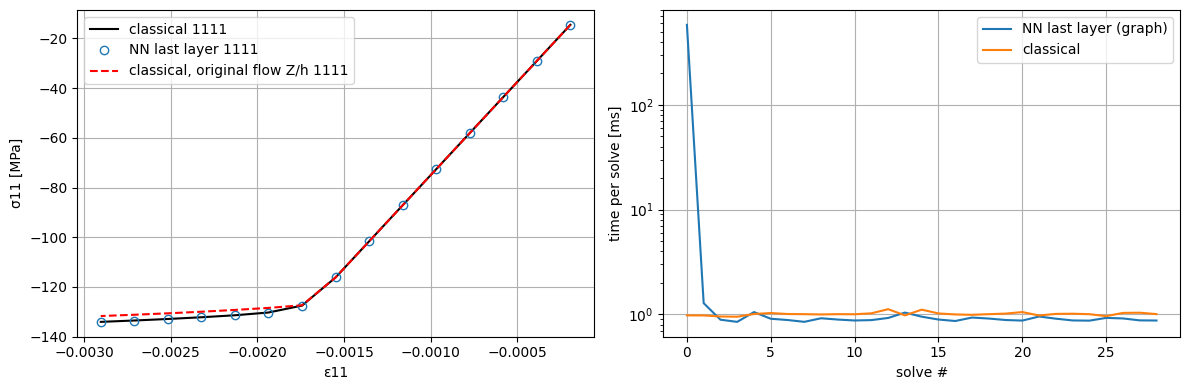

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for (l, m, n) in POINTS:
    key = str(i+1) + str(l+1) + str(m+1) + str(n+1)
    e_nn, s_nn = np.array(mp_nn['abs_strain'+key]), np.array(mp_nn['abs_stress'+key])
    e_cl, s_cl = np.array(mp_cl['abs_strain'+key]), np.array(mp_cl['abs_stress'+key])
    axs[0].plot(e_cl[:, 0], s_cl[:, 0], 'k-', label=f'classical {key}')
    axs[0].plot(e_nn[:, 0], s_nn[:, 0], 'o', mfc='none', label=f'NN last layer {key}')
    e_ch, s_ch = np.array(mp_ch['abs_strain'+key]), np.array(mp_ch['abs_stress'+key])
    axs[0].plot(e_ch[:, 0], s_ch[:, 0], 'r--', label=f'classical, original flow Z/h {key}')
axs[0].set_xlabel('ε11'); axs[0].set_ylabel('σ11 [MPa]'); axs[0].legend(); axs[0].grid()
axs[1].semilogy(1e3 * df.time_nn.values[1:], label='NN last layer (graph)')
axs[1].semilogy(1e3 * df.time_classical.values[1:], label='classical')
axs[1].set_xlabel('solve #'); axs[1].set_ylabel('time per solve [ms]'); axs[1].legend(); axs[1].grid()
plt.tight_layout(); plt.show()